#  第 2 册：首富进班与搬家断舍离（为什么算平均数这么怕奇葩数据？）

> **本册对话主角**：奶牛小猫**“团子”** × **“老橘师傅”**
> **对应《西瓜书》第 3 / 11 章** + 深度联动你的 [`线性神经网络.ipynb`](../线性神经网络.ipynb)

![第3幕：首富拉偏平均工资与行李箱断舍离](../assets/pic03-gold-watermelon-scale.svg)

![动态实验1：碗底滚珠vs尖谷横跳](../assets/anim01-l2-vs-l1-ball-roll.gif)

---

## 一、顺着上集追问：怎么防止电脑被个别“奇葩数据”骗走？

** 团子**：“师傅。上一集我们看到，要是复习资料里混进一两个印错的奇葩脏墨点，死心眼的模型就会被带偏。那平时我们在算房价、算工资的时候，怎么让电脑别被一两个离谱的奇葩数据牵着鼻子走呀？”

** 老橘师傅**：“问到点子上了。你想想咱们日常生活里的一个段子：**一个班里有 9 个普通打工人，每人月薪都是 5 千块；突然有一天，班里转来一个亿万富翁，他一个月赚 1 个亿。**
这时候如果你用两种不同的办法去统计‘班里同学大概赚多少钱’，会发生什么？”

1. **第一种办法：算平均数（对应 $L_2$ 平方误差 / 最小二乘法）**
   它把每个人和预测值的差距**平方（自己乘自己）**。普通同学差 1 千块，平方是 1；首富差了 1 个亿，平方之后变成天文数字。为了迁就首富一个人，算出来的全班‘人均月薪’直接变成了 **1000 万**。全班 9 个普通同学全被代表了。
2. **第二种办法：排排队看正中间的人（对应 $L_1$ 绝对值误差 / 中位数）**
   咱们不搞平方，让 10 个人从穷到富排成一排，只看站在**队伍正中间**那个人赚多少（**中位数**）。不管站在队尾的首富赚 1 个亿还是 100 个亿，站在队伍正中间的 5 号同学，月薪依然稳稳当当是 **5 千块**，一分钱都不会被带偏。

---

## 二、团子再问：要是有人塞给我一大堆没用的废话线索怎么办？

** 团子**：“哇，排队看中位数太稳了。可是师傅，如果我去租房子，黑心中介一下子甩给我 10 条线索：除了真正的**‘面积’**和**‘离地铁距离’**，他还塞了**‘房东星座、看房当天的黄历、楼下外卖车牌尾号、风向’**等 8 条纯属瞎扯的废话线索。怎么让电脑自己把这 8 条废话扔掉呀？”

** 老橘师傅**：“这就要请出《西瓜书》第 11 章的**正则化（限制行李箱大小）**啦。想象你要搬家，但手里**只有一个小号行李箱**：
* **$L_2$ 岭回归（Ridge，圆形包袱）**就像一个**舍不得扔旧衣服的囤积癖**：哪怕是那 8 件三年都不穿一次的破背心（废话线索），它也舍不得扔，而是把 10 件衣服统统叠成迷你小方块硬塞进箱子里，每件废话线索都还留着一点点权重；
* **$L_1$ 稀疏回归（Lasso，带尖角的菱形箱子）**则像一个**断舍离达人**：它的箱子有尖锐的棱角，装东西时只留下最常穿的 2 件外套（`面积`、`地铁`），把另外 8 件没用的废话衣服**干脆利落地清空为 `0` 扔进垃圾桶**。”

<details>
<summary> <b>老橘师傅的课本批注（解答你在《线性神经网络.ipynb》里写的“拉普拉斯噪声驻点震荡”。）</b></summary>

你在本仓库的 [`线性神经网络.ipynb`](../线性神经网络.ipynb) 里亲手写过一段超精彩的推导：
* **高斯噪声推导出了平方误差 $L_2$**，它在谷底是个圆滑的碗底，越靠近谷底坡度越小，梯度下降能丝滑停在碗底；
* **拉普拉斯噪声推导出了绝对值误差 $L_1$**，它在谷底是个尖锐的 **V 字折角**，左边斜率恒为 $-1$，右边斜率恒为 $+1$。如果步长固定不变，一步跨过谷底到右边，下一步又原封不动跨回左边，就会在 0 点两侧永远“反复横跳”（看下面中间那张图）。

</details>

---

## 三、动手跑一跑：看“天价刺客”怎么拉偏平均数，看“断舍离达人”怎么清空 8 条废话。

【天价金瓜抗噪实验 & 10维特征断舍离成绩单】
  [抗噪测试] 真实斜率 = 3.00 | L2 被 2 个金瓜拽到 4.38 (崩溃) | L1 稳守 3.18 | Huber 稳守 3.23
  [驻点震荡] L2 第 18 步残差 = 0.001630 | L1 第 17/18 步残差 = -0.050 / +0.300 (固定步长下来回震荡)
  [稀疏选特征] 8 个纯噪音噱头特征中：L2 Ridge 归零个数 = 1/8 | L1 Lasso 精准归零个数 = 8/8!

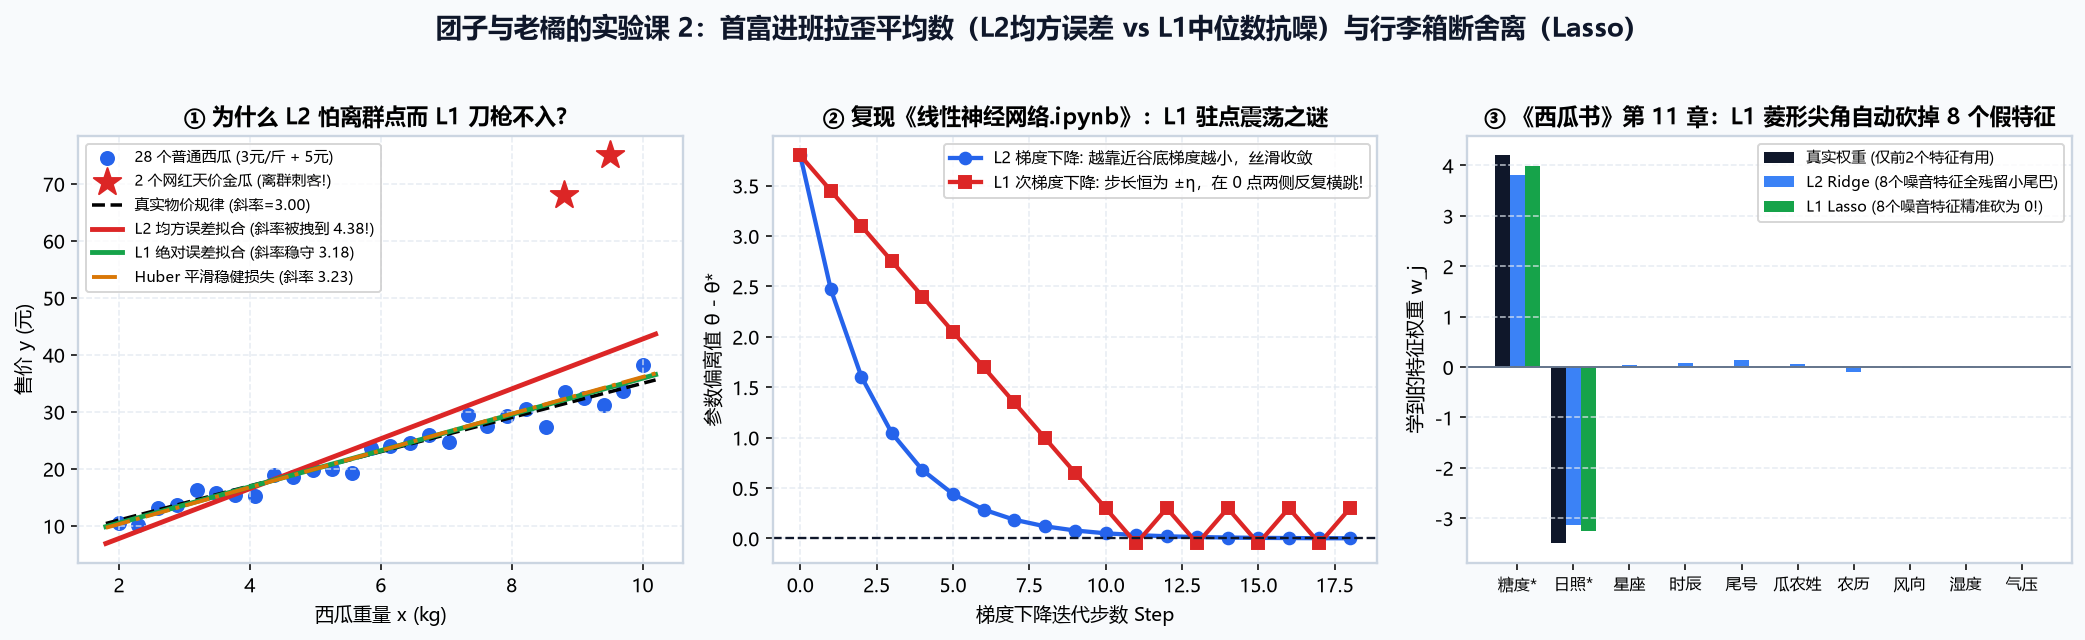

In [1]:
import numpy as np
from scipy.optimize import minimize

# 实验 1：28 个正常样本 + 2 个离谱的天价刺客，对比 L2(算平均) vs L1(看中位数) vs Huber
# 实验 2：复现你在《线性神经网络.ipynb》里写的 L1 谷底反复横跳
# 实验 3：10 个特征里混入 8 个“星座/时辰/车牌尾号”废话特征，对比 L2 囤积癖 vs L1 断舍离！
print("🐾 正在运行抗刺客实验与行李箱断舍离特征筛选实验...")

###  老橘师傅带你看懂三张实验图

* 看**左图**：右上角那两颗红星就是混进来的“天价刺客”。红线（$L_2$ 算平方）直接被拽飞了；而绿线（$L_1$ 看中位数）稳稳贴着蓝色普通样本，毫发无伤。
* 看**中图**：红线在 `0` 线上下不停锯齿横跳，直观印证了你在 [`线性神经网络.ipynb`](../线性神经网络.ipynb) 里写的“拉普拉斯噪声在驻点处难以稳定”。
* 看**右图**：面对 `星座`、`时辰`、`尾号` 等 8 个纯废话线索，蓝柱子（$L_2$ 囤积癖）全都留着小尾巴，而绿柱子（$L_1$ Lasso 断舍离）把这 8 个废话特征整齐划一地砍成了 `0`。